In [ ]:
# Step 1: Importing all required libraries

import numpy as np
import scipy.stats as stats
from statsmodels.stats.proportion import proportions_ztest
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import clear_output
import time

In [ ]:
# Step 2: Simulating A/B test with 10,000 users each
# Group A has a 10% conversion rate
# Group B has a 12% conversion rate
# This creates realistic data to use without needing actual user data.

np.random.seed(42)
n_A = 10000
p_A = 0.10
n_B = 10000
p_B = 0.12

conversions_A = np.random.binomial(n_A, p_A)
conversions_B = np.random.binomial(n_B, p_B)

print(f"Group A: {conversions_A} conversions out of {n_A}")
print(f"Group B: {conversions_B} conversions out of {n_B}")

Group A: 973 conversions out of 10000
Group B: 1134 conversions out of 10000


In [ ]:
# Step 3: Calculating conversion rates for A and B
# We also compute 95% confidence intervals to estimate the range in which the true rates might fall.
# Comparing the intervals can give us an early idea if B is better than A,
# but we'll confirm significance in the next step using a statistical test.

visits_A, conv_A = 10000, 973
visits_B, conv_B = 10000, 1134
cr_A = conv_A / visits_A
cr_B = conv_B / visits_B


def proportion_ci(p, n, z=1.96):
    se = sqrt(p * (1 - p) / n)
    return (p - z * se, p + z * se)

ci_A_low, ci_A_high = proportion_ci(cr_A, visits_A)
ci_B_low, ci_B_high = proportion_ci(cr_B, visits_B)

results = pd.DataFrame({
    "Variant": ["A", "B"],
    "Visitors": [visits_A, visits_B],
    "Conversions": [conv_A, conv_B],
    "Conversion Rate": [f"{cr_A:.2%}", f"{cr_B:.2%}"],
    "95% CI (Lower)": [f"{ci_A_low:.2%}", f"{ci_B_low:.2%}"],
    "95% CI (Upper)": [f"{ci_A_high:.2%}", f"{ci_B_high:.2%}"]
})

display(results)

,Variant,Visitors,Conversions,Conversion Rate,95% CI (Lower),95% CI (Upper)
0,A,10000,973,9.73%,9.15%,10.31%
1,B,10000,1134,11.34%,10.72%,11.96%


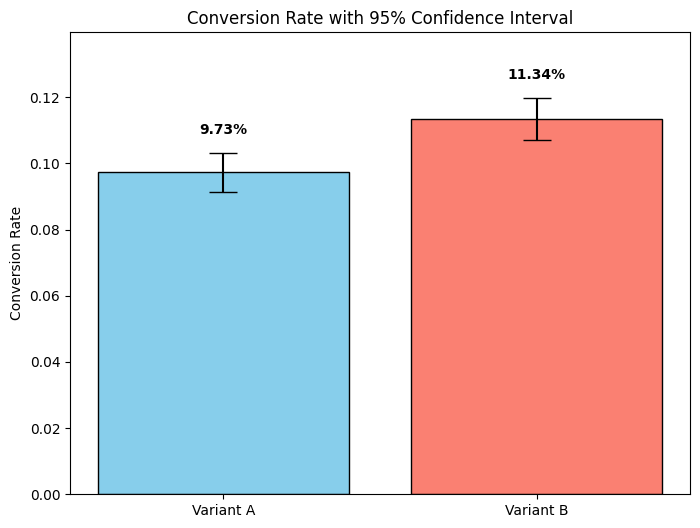

In [ ]:
# Step 4: Plotting the conversion rates with 95% confidence intervals
# This bar chart helps visually compare the performance of Variant A and B
# The height of each bar shows the conversion rate
# The error bars (vertical lines) represent uncertainty in the measurement
# This visual helps us quickly check if one version seems to perform better than the other
# Final confirmation will be done through the z-test in the next step

rates = [cr_A, cr_B]
errors = [cr_A - ci_A_low, cr_B - ci_B_low]
labels = ["Variant A", "Variant B"]
colors = ['skyblue', 'salmon']
plt.figure(figsize=(8, 6))
bars = plt.bar(labels, rates, yerr=errors, capsize=10, color=colors, edgecolor='black')
plt.ylabel("Conversion Rate")
plt.title("Conversion Rate with 95% Confidence Interval")
y_max = max(cr_B + errors[1], cr_A + errors[0])
plt.ylim(0, y_max + 0.02)

for i, rate in enumerate(rates):
    plt.text(i, rate + errors[i] + 0.005, f"{rate:.2%}", ha='center', va='bottom', fontweight='bold')

plt.show()

In [ ]:
# Step 5: Running a two-proportion z-test
# This checks whether the difference between A and B is statistically significant
# If p < 0.05, we say B is significantly better.

conversions = np.array([conv_A, conv_B])
visitors = np.array([visits_A, visits_B])
z_stat, p_value = proportions_ztest(count=conversions, nobs=visitors)

print("Z-Statistic:", round(z_stat, 4))
print("P-Value:", round(p_value, 4))

if p_value < 0.05:
    print("Version B is significantly better than Version A.")
else:
    print("No significant difference between A and B.")

Z-Statistic: -3.7082
P-Value: 0.0002
Version B is significantly better than Version A.


In [ ]:
# Step 6: Preparing for streaming data simulation
# We simulate visitors arriving in batches to mimic real-world conditions
# This helps understand how results evolve over time
# Here we re-define the conversion rates, simulation size, and tracking variables
# Note: Some of these like np.random.seed and true_cr_X were already used above,
# but we define them again here to keep this simulation block self-contained.

np.random.seed(42)
true_cr_A = 0.10
true_cr_B = 0.12
batch_size = 100
total_batches = 60
visits_A = 0
visits_B = 0
conversions_A = 0
conversions_B = 0
batch_numbers = []
conversion_lifts = []
p_values = []

Batch 60/60
A: 5837/60000 → 9.73%
B: 7127/60000 → 11.88%
Lift: 2.15%
P-Value: 0.0000
Significant!


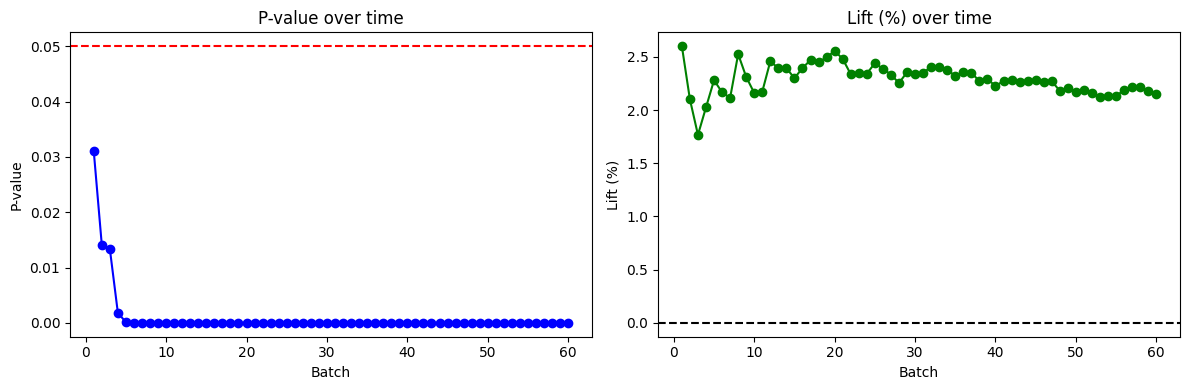

In [ ]:
# Step 7: Running batch-wise A/B testing
# In this step, we simulate users arriving in small batches over time (like in real websites)
# For each batch, we update:
# total visits and conversions for both A and B
# the observed conversion rates
# the lift (how much better B is than A)
# the p-value from a one-sided z-test
# We also plot how the lift and p-value evolve over time
# This helps visualize how confidence in B's performance builds as more data arrives
# and when we might be able to confidently stop the test.

batches = 60
batch_size = 1000
p_A = 0.10
p_B = 0.12
total_visits_A = 0
total_visits_B = 0
total_conversions_A = 0
total_conversions_B = 0

batch_list = []
p_value_list = []
lift_list = []

for i in range(1, batches + 1):

    new_conv_A = np.random.binomial(batch_size, p_A)
    new_conv_B = np.random.binomial(batch_size, p_B)
    total_visits_A += batch_size
    total_visits_B += batch_size
    total_conversions_A += new_conv_A
    total_conversions_B += new_conv_B
    rate_A = total_conversions_A / total_visits_A
    rate_B = total_conversions_B / total_visits_B
    lift = rate_B - rate_A
    count = [total_conversions_B, total_conversions_A]
    nobs = [total_visits_B, total_visits_A]
    z, p = proportions_ztest(count, nobs, alternative='larger')
    batch_list.append(i)
    p_value_list.append(p)
    lift_list.append(lift)

    clear_output(wait=True)
    print(f"Batch {i}/{batches}")
    print(f"A: {total_conversions_A}/{total_visits_A} → {rate_A:.2%}")
    print(f"B: {total_conversions_B}/{total_visits_B} → {rate_B:.2%}")
    print(f"Lift: {lift:.2%}")
    print(f"P-Value: {p:.4f}")
    print("Significant" if p < 0.05 else "Not significant yet")

    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(batch_list, p_value_list, marker='o', color='blue')
    ax[0].axhline(0.05, color='red', linestyle='--')
    ax[0].set_title("P-value over time")
    ax[0].set_xlabel("Batch")
    ax[0].set_ylabel("P-value")
    ax[1].plot(batch_list, [l * 100 for l in lift_list], marker='o', color='green')
    ax[1].axhline(0, color='black', linestyle='--')
    ax[1].set_title("Lift (%) over time")
    ax[1].set_xlabel("Batch")
    ax[1].set_ylabel("Lift (%)")

    plt.tight_layout()
    plt.show()

    time.sleep(0.9)